#### Category Classifier

##### Importing Packages and Loading Data

In [22]:
# Libraries; planscope imports work because the package is installed in editable mode

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

from transformers import pipeline

from planscope.category_data import reference_code
from planscope.evaluate import evaluate, macro_f1

from pathlib import Path

from planscope.classifier import CategoryClassifier

df = pd.read_parquet('../data/processed/applications.parquet')

In [2]:
# % of applications with no category, by year submitted: the field arrived around 2021

df['category'].isna().groupby(df['valid_date'].dt.year).mean().mul(100).round(0)

valid_date
2019    93.0
2020    82.0
2021    19.0
2022    13.0
2023     9.0
2024     8.0
2025     9.0
2026    13.0
Name: category, dtype: float64

In [3]:
# The same description can go through different legal routes

text = df['description'].str.lower().str.rstrip('.')
df.loc[text == 'single storey rear extension', 'category'].value_counts(normalize=True).round(2)

category
householder           0.82
lawful_development    0.09
full_planning         0.06
prior_approval        0.03
Name: proportion, dtype: float64

In [4]:
# Ceiling for any text-only model: how often a repeated description's most common category is right

lab = df[df['category'].notna() & df['description'].notna()].assign(text=text)
repeated = lab[lab.duplicated('text', keep=False)]
repeated.groupby('text')['category'].agg(lambda s: s.value_counts().iloc[0]).sum() / len(repeated)

np.float64(0.9118746262706797)

In [6]:
# Council reference codes are reliable labels, e.g. Barnet's HSE

code = reference_code(df['lpa_app_no'])
df.loc[(df['lpa_name'] == 'Barnet') & (code == 'HSE'), 'category'].value_counts(normalize=True).round(2).head(5)

category
householder      0.99
full_planning    0.01
Name: proportion, dtype: float64

##### Task decisions
- **Job:** predict the category (legal route) from the description, to fill the ~31% of applications without one (mostly 2019–2020, before the form field existed).
- **Training data:** distinct descriptions from labelled applications, each with its most common category (majority vote); 'other' (123 rows) excluded. Split 80/10/10 at random: 409,961 / 51,245 / 51,246.
- **Second test set (missing_test):** 90,215 unlabelled applications from 18 authorities, labelled by council reference codes that mean one category at least 95% of the time across 30+ labelled examples. It measures the real job, including the shift in period and category mix.
- **Ceiling:** identical descriptions carry different categories, so a text-only model can't exceed about 91% accuracy. The classifier reports the most likely category with its probability.

##### TF-IDF + Logistic Regression

In [8]:
# Load the four datasets built by category_data.py

sets = {name: pd.read_parquet(f'../data/processed/category/{name}.parquet') for name in ['train', 'val', 'test', 'missing_test']}
train, val = sets['train'], sets['val']

In [9]:
# Turn text into TF-IDF features: single words and word pairs seen in at least 2 training texts

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(train['text'])
X_val = vectorizer.transform(val['text'])
X_train.shape

(410023, 376608)

In [10]:
# Choose the regularization strength C by validation macro-F1

best_score, model = 0, None
for C in [1, 4, 16]:
    candidate = LogisticRegression(C=C, max_iter=1000).fit(X_train, train['category'])
    score = macro_f1(val['category'], candidate.predict(X_val))
    print(f'C={C}: validation macro-F1 {score:.4f}')
    if score > best_score:
        best_score, model = score, candidate

C=1: validation macro-F1 0.8707
C=4: validation macro-F1 0.8756
C=16: validation macro-F1 0.8739


In [11]:
# Score both test sets with confidence intervals, and time the predictions

results = {}
for name in ['test', 'missing_test']:
    data = sets[name]
    start = time.perf_counter()
    sets[name] = data.assign(predicted=model.predict(vectorizer.transform(data['text'])))
    print(f'{name}: {(time.perf_counter() - start) / len(data) * 1e6:.0f} ms per 1,000 descriptions')
    results[name] = evaluate(data['category'], sets[name]['predicted'])
pd.concat(results)

test: 31 ms per 1,000 descriptions
missing_test: 27 ms per 1,000 descriptions


score  ci_low  ci_high
test         accuracy   0.89    0.89     0.90
             macro_f1   0.88    0.87     0.88
missing_test accuracy   0.92    0.92     0.92
             macro_f1   0.92    0.92     0.92

In [12]:
# Precision, recall and F1 for each category on the test set

print(classification_report(sets['test']['category'], sets['test']['predicted'], digits=3))

                    precision    recall  f1-score   support

            advert      0.831     0.889     0.859      1308
         amendment      0.966     0.928     0.947      1798
        conditions      0.985     0.982     0.983      9896
     full_planning      0.848     0.831     0.839     12510
       householder      0.823     0.885     0.853     12106
lawful_development      0.912     0.850     0.880      5867
   listed_building      0.734     0.501     0.596       704
    prior_approval      0.976     0.931     0.953      2171
             trees      0.974     0.986     0.980      4893

          accuracy                          0.895     51253
         macro avg      0.894     0.865     0.877     51253
      weighted avg      0.895     0.895     0.894     51253



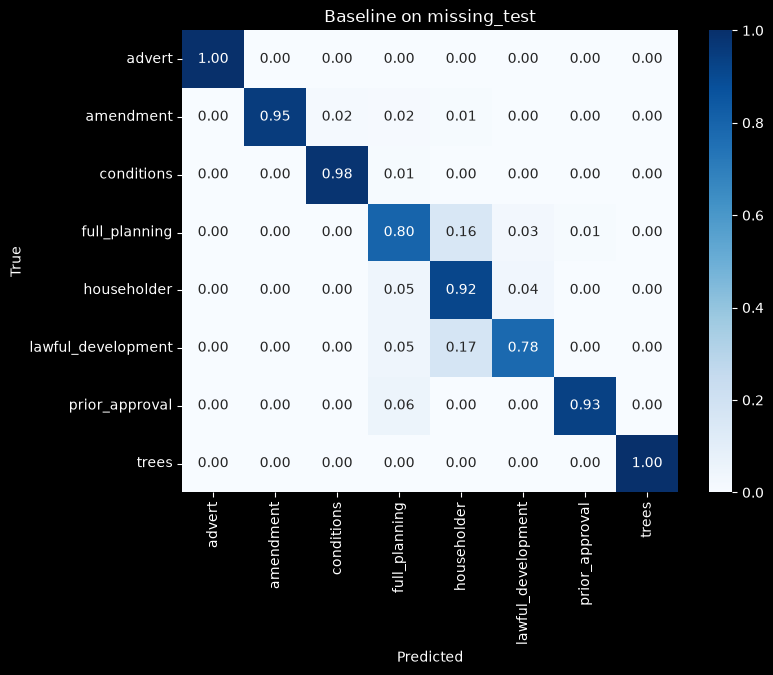

In [14]:
# Which categories get mistaken for which on missing_test (each row sums to 1)

labels = sorted(sets['missing_test']['category'].unique())

cm = confusion_matrix(sets['missing_test']['category'], sets['missing_test']['predicted'], labels=labels, normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Baseline on missing_test')
plt.show()

In [15]:
# The six words or word pairs that most strongly signal each category

words = vectorizer.get_feature_names_out()
top = {category: words[np.argsort(weights)[-6:][::-1]] for category, weights in zip(model.classes_, model.coef_)}
pd.DataFrame(top).T

,0,1,2,3,4,5
advert,illuminated,signage,advertisement,display,sign,measuring
amendment,non material,nma,non,to planning,amendment,namely
conditions,condition,details,conditions,of condition,pursuant,pursuant to
full_planning,of,and,shopfront,to,display of,flats
householder,of,to,garage,retrospective,front,extension
lawful_development,certificate,lawful,certificate of,lawfulness,use,of lawfulness
listed_building,internal,adv,and,to,of,listed
prior_approval,prior,prior approval,eaves,demolition,approval for,flats
trees,fell,tree,prune,t1,tpo,trees


In [16]:
# Accuracy on missing_test by authority

sets['missing_test'].assign(correct=sets['missing_test']['category'] == sets['missing_test']['predicted']).groupby('lpa_name')['correct'].agg(['size', 'mean']).sort_values('mean').round(3)

,size,mean
lpa_name,,
Croydon,9808,0.842
Richmond,10617,0.865
Enfield,8044,0.865
Barking & Dagenham,582,0.887
Bexley,1920,0.898
Kingston,4128,0.901
Barnet,9045,0.902
Greenwich,5867,0.923
Newham,5195,0.940


In [17]:
# The model outputs a probability for every category, not just one answer

examples = ['single storey rear extension', 'erection of a five storey building comprising 20 flats', 'prune 1 x oak tree']
pd.DataFrame(model.predict_proba(vectorizer.transform(examples)), index=examples, columns=model.classes_).round(2)

,advert,amendment,conditions,full_planning,householder,lawful_development,listed_building,prior_approval,trees
single storey rear extension,0.00,0.00,0.00,0.01,0.89,0.02,0.0,0.08,0.0
erection of a five storey building comprising 20 flats,0.01,0.01,0.06,0.85,0.00,0.06,0.0,0.00,0.0
prune 1 x oak tree,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,1.0


##### Baseline results
- **Settings:** word and word-pair TF-IDF (min_df=2, sublinear tf), logistic regression with C=4 chosen on validation (C=1: 0.8701, C=4: 0.8765, C=16: 0.8735). Single words only (0.8686) and balanced class weights (0.861–0.872) were tested and were worse.
- **test:** accuracy 0.893 (95% CI 0.890–0.895), macro-F1 0.875 (0.871–0.880).
- **missing_test:** accuracy 0.917 (0.916–0.919), macro-F1 0.918 (0.915–0.920). This subset is heavy on easy categories (conditions, trees) and has no listed buildings, so it is likely easier than the full unlabelled population; the test score is the conservative estimate.
- **Weak spots:** listed_building (F1 0.58); full_planning and lawful_development are often predicted as householder (16% and 17% on missing_test), the legal-route ambiguity measured above.
- **Limitation:** function words ("of", "to", "and") carry weight, so the model partly learns writing style rather than meaning.
- **Cost:** trains in about 5 minutes on a CPU; predicts at about 40 ms per 1,000 descriptions.

##### Fine-Tuned DistilBERT

In [19]:
# Load the fine-tuned model as a ready-made text-classification pipeline on the GPU

classifier = pipeline('text-classification', model='../models/category-distilbert', device=0)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [20]:
# Score both test sets exactly as the baseline was scored, and time the predictions

distil_results = {}
for name in ['test', 'missing_test']:
    data = sets[name]
    start = time.perf_counter()
    predicted = [p['label'] for p in classifier(data['text'].tolist(), batch_size=256, truncation=True, max_length=128)]
    print(f'{name}: {(time.perf_counter() - start) / len(data) * 1e6:.0f} ms per 1,000 descriptions (GPU)')
    sets[name] = data.assign(distil=predicted)
    distil_results[name] = evaluate(data['category'], predicted)
pd.concat({'baseline': pd.concat(results), 'distilbert': pd.concat(distil_results)}, axis=1)

test: 2216 ms per 1,000 descriptions (GPU)
missing_test: 1977 ms per 1,000 descriptions (GPU)


baseline                distilbert               
                         score ci_low ci_high      score ci_low ci_high
test         accuracy     0.89   0.89    0.90       0.91   0.90    0.91
             macro_f1     0.88   0.87    0.88       0.89   0.89    0.90
missing_test accuracy     0.92   0.92    0.92       0.92   0.92    0.93
             macro_f1     0.92   0.92    0.92       0.93   0.92    0.93

In [21]:
# F1 per category on the test set: baseline vs DistilBERT

test = sets['test']
f1 = {model: pd.DataFrame(classification_report(test['category'], test[col], output_dict=True)).T['f1-score'] for model, col in [('baseline', 'predicted'), ('distilbert', 'distil')]}
pd.DataFrame(f1).round(3)

,baseline,distilbert
advert,0.859,0.880
amendment,0.947,0.965
conditions,0.983,0.987
full_planning,0.839,0.854
householder,0.853,0.864
lawful_development,0.880,0.893
listed_building,0.596,0.666
prior_approval,0.953,0.960
trees,0.980,0.983
accuracy,0.895,0.906


##### DistilBERT results
- **Training:** distilbert-base-uncased, 2 epochs, learning rate 5e-5, batch 64, bf16, 128-token cap; best epoch chosen on validation macro-F1 (epoch 1: 0.887, epoch 2: 0.897). Validation loss still falling (0.275 → 0.261), so no overfitting. 12 minutes on an RTX 5060 laptop GPU.
- **test:** accuracy 0.906 [CI], macro-F1 0.895 [CI], against the baseline's 0.895 / 0.877. The gain is several times the interval width, so it is real.
- **missing_test:** accuracy [score, CI], macro-F1 [score, CI]. Small gain, because this subset is dominated by categories both models already get almost entirely right.
- **Per category:** better everywhere; largest gain on listed_building (0.596 → 0.666), where context matters most.
- **Cost:** about 2.2 s per 1,000 descriptions on the GPU, roughly 70× slower than the baseline on a CPU. CPU cost to be measured after ONNX export.
- **Decision:** DistilBERT goes forward to deployment; remaining errors are mostly irreducible legal-route ambiguity.

##### ONNX on CPU

In [23]:
# Model file sizes in MB: PyTorch weights vs ONNX fp32 vs ONNX int8

files = {
    'pytorch': '../models/category-distilbert/model.safetensors',
    'onnx_fp32': '../models/category-onnx/model.onnx',
    'onnx_int8': '../models/category-onnx/model.int8.onnx',
}
pd.Series({name: Path(path).stat().st_size / 1e6 for name, path in files.items()}).round(1)

pytorch      267.9
onnx_fp32    268.5
onnx_int8     67.8
dtype: float64

In [24]:
# CPU classifiers on the exported models

onnx_fp32 = CategoryClassifier('../models/category-onnx', 'model.onnx')
onnx_int8 = CategoryClassifier('../models/category-onnx')

In [25]:
# Agreement with the PyTorch model on 1,000 test descriptions

sample = sets['test'].head(1000)
pd.Series({name: (sample['distil'] == clf.predict(sample['text'].tolist())[0]).mean() for name, clf in [('onnx_fp32', onnx_fp32), ('onnx_int8', onnx_int8)]})

onnx_fp32    1.000
onnx_int8    0.989
dtype: float64

In [26]:
# Score the int8 model on both test sets (CPU)

int8_results = {}
for name in ['test', 'missing_test']:
    data = sets[name]
    start = time.perf_counter()
    predicted, _ = onnx_int8.predict(data['text'].tolist())
    print(f'{name}: {(time.perf_counter() - start) / len(data) * 1e6:.0f} ms per 1,000 descriptions (CPU, int8)')
    sets[name] = data.assign(int8=predicted)
    int8_results[name] = evaluate(data['category'], predicted)
pd.concat({'baseline': pd.concat(results), 'distilbert': pd.concat(distil_results), 'int8': pd.concat(int8_results)}, axis=1)

test: 5414 ms per 1,000 descriptions (CPU, int8)
missing_test: 4555 ms per 1,000 descriptions (CPU, int8)


baseline                distilbert                 int8  \
                         score ci_low ci_high      score ci_low ci_high score   
test         accuracy     0.89   0.89    0.90       0.91   0.90    0.91  0.91   
             macro_f1     0.88   0.87    0.88       0.89   0.89    0.90  0.90   
missing_test accuracy     0.92   0.92    0.92       0.92   0.92    0.93  0.92   
             macro_f1     0.92   0.92    0.92       0.93   0.92    0.93  0.93   

                                      
                      ci_low ci_high  
test         accuracy   0.90    0.91  
             macro_f1   0.89    0.90  
missing_test accuracy   0.92    0.92  
             macro_f1   0.92    0.93

In [27]:
# Latency for one description on CPU (what an API request costs): median of 200 requests, in ms

def median_ms(predict_one):
    times = []
    for text in sets['test']['text'].head(200):
        start = time.perf_counter()
        predict_one(text)
        times.append(time.perf_counter() - start)
    return np.median(times) * 1000


pd.Series({
    'baseline': median_ms(lambda text: model.predict(vectorizer.transform([text]))),
    'onnx_fp32': median_ms(lambda text: onnx_fp32.predict([text])),
    'onnx_int8': median_ms(lambda text: onnx_int8.predict([text])),
}).round(4)

baseline     0.58
onnx_fp32    7.37
onnx_int8    3.54
dtype: float64

##### Deployment decision
- **Sizes:** PyTorch 268 MB, ONNX fp32 269 MB, ONNX int8 68 MB.
- **Agreement with PyTorch:** fp32 1.000, int8 0.989 (1,000 test descriptions).
- **Accuracy:** int8 matches DistilBERT within the confidence intervals on both test sets (test macro-F1 [score, CI] vs [score, CI]).
- **CPU latency per description:** baseline 0.58 ms, fp32 7.4 ms, int8 3.5 ms.
- **Decision:** deploy int8: as accurate, 4× smaller, 2× faster. Predictions run one description at a time, so bulk results match the API exactly.
- **Filled:** 278,107 missing categories (data/processed/categories.parquet), with model confidence.